In [1]:
import pandas as pd
import numpy as np
df = pd.read_csv('Telco-Customer-Churn.csv')
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [3]:
df.sample(7)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
2101,2153-MREFK,Female,0,Yes,No,37,Yes,Yes,Fiber optic,Yes,...,Yes,Yes,No,Yes,One year,Yes,Electronic check,99.20,3754.6,Yes
1746,3963-RYFNS,Female,0,No,No,72,Yes,Yes,Fiber optic,Yes,...,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),116.45,8013.55,No
4281,8582-KRHPJ,Male,0,No,No,50,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,35.00,1782.4,No
3950,5655-JSMZM,Male,1,No,No,49,Yes,Yes,Fiber optic,No,...,No,No,Yes,Yes,Month-to-month,Yes,Electronic check,96.20,4718.25,Yes
3659,0795-GMVQO,Male,0,Yes,No,67,Yes,Yes,Fiber optic,Yes,...,Yes,No,Yes,Yes,One year,No,Credit card (automatic),109.90,7332.4,No
6060,4884-ZTHVF,Female,1,No,No,8,Yes,No,Fiber optic,No,...,No,No,Yes,No,Month-to-month,Yes,Electronic check,87.10,713.6,No
2510,3707-GNWHM,Male,0,No,No,1,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.25,74.25,Yes


In [4]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'].replace(' ',''),errors='coerce')

In [5]:
df.drop('customerID',axis=1,inplace=True)

In [6]:
df['Churn'] = df['Churn'].map({'Yes': 1,'No' : 0})
df['Churn'].unique()

array([0, 1])

In [7]:
categorical_cols = df.select_dtypes(include=['object']).columns
df_encoded = pd.get_dummies(df,columns=categorical_cols,drop_first=True)

/tmp/ipykernel_14941/2554418238.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(include=['object']).columns


In [8]:
df.shape

(7043, 20)

In [9]:
df_encoded.shape

(7043, 31)

In [10]:
X = df_encoded.drop('Churn',axis=1)
y = df_encoded['Churn']

In [11]:
from sklearn.model_selection import train_test_split
X_train , X_test , y_train , y_test = train_test_split(X,y,test_size=0.2,random_state=42)

In [12]:
X_train.shape

(5634, 30)

In [13]:
X_test.shape

(1409, 30)

In [14]:
train_median = X_train['TotalCharges'].median()
X_train['TotalCharges'] = X_train['TotalCharges'].fillna(train_median)
X_test['TotalCharges'] = X_test['TotalCharges'].fillna(train_median)

In [15]:
X_train['Calculated_Monthly'] = X_train['TotalCharges'] /( X_train['tenure'] + 1)
X_test['Calculated_Monthly'] = X_test['TotalCharges'] / (X_test['tenure'] + 1)

In [16]:
train_data = X_train.copy()
train_data['Churn'] = y_train

In [17]:
correlations = train_data.corr()['Churn'].sort_values()
weak_features = correlations[abs(correlations) < 0.05].index.to_list()

In [18]:
correlations

tenure                                  -0.344925
Contract_Two year                       -0.299840
OnlineSecurity_No internet service      -0.224203
OnlineBackup_No internet service        -0.224203
TechSupport_No internet service         -0.224203
StreamingMovies_No internet service     -0.224203
DeviceProtection_No internet service    -0.224203
InternetService_No                      -0.224203
StreamingTV_No internet service         -0.224203
TotalCharges                            -0.194186
Contract_One year                       -0.174912
OnlineSecurity_Yes                      -0.172149
TechSupport_Yes                         -0.162722
Dependents_Yes                          -0.162356
Partner_Yes                             -0.142266
PaymentMethod_Credit card (automatic)   -0.135167
PaymentMethod_Mailed check              -0.092425
OnlineBackup_Yes                        -0.081422
DeviceProtection_Yes                    -0.063291
gender_Male                             -0.011729


In [19]:
weak_features

['gender_Male',
 'MultipleLines_No phone service',
 'PhoneService_Yes',
 'Calculated_Monthly',
 'MultipleLines_Yes']

In [20]:
if 'Churn' in weak_features:
    weak_features.remove('Churn')

In [21]:
X_train = X_train.drop(columns=weak_features)
X_test = X_test.drop(columns=weak_features)

In [22]:
X_train.shape

(5634, 26)

In [23]:
X_test.shape

(1409, 26)

In [24]:
import xgboost as xgb
model = xgb.XGBClassifier(random_state=42,eval_metric='logloss')
model.fit(X_train,y_train)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'logloss'
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [25]:
from sklearn.metrics import accuracy_score,classification_report
y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test,y_pred)
print(f"{accuracy*100:.2f}")

79.91


In [26]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.84      0.89      0.87      1036
           1       0.64      0.54      0.59       373

    accuracy                           0.80      1409
   macro avg       0.74      0.72      0.73      1409
weighted avg       0.79      0.80      0.79      1409



In [27]:
from imblearn.over_sampling import SMOTE
print(f"Before SMOTE - Churners : {sum(y_train==1)},Loyal: {sum(y_train==0)}")
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train,y_train)
print(f"After SMOTE - Churners : {sum(y_train_smote==1)},Loyal: {sum(y_train_smote==0)}")

Before SMOTE - Churners : 1496,Loyal: 4138
After SMOTE - Churners : 4138,Loyal: 4138


In [28]:
from sklearn.model_selection import RandomizedSearchCV

param_grid = {
    'max_depth' : [3,4,5,6],
    'learning_rate' : [0.01,0.05,0.1,0.2],
    'n_estimators' : [100,200,300],
    'subsample' : [0.8,0.9,1.0]
}

xgb_base = xgb.XGBClassifier(random_state=42,eval_metric='logloss')

In [29]:
random_search = RandomizedSearchCV(xgb_base,param_distributions=param_grid,n_iter=15,scoring='accuracy',cv=3,random_state=42)
random_search.fit(X_train_smote,y_train_smote)

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","XGBClassifier...ree=None, ...)"
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'learning_rate': [0.01, 0.05, ...], 'max_depth': [3, 4, ...], 'n_estimators': [100, 200, ...], 'subsample': [0.8, 0.9, ...]}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",15
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'accuracy'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for

In [30]:
best_model = random_search.best_estimator_
print(f"\nBest Parameters found : {random_search.best_params_}")


Best Parameters found : {'subsample': 0.8, 'n_estimators': 200, 'max_depth': 6, 'learning_rate': 0.05}


In [31]:
y_pred_tuned = best_model.predict(X_test)
print(f"\nOptimized Model Accuracy: {accuracy_score(y_test, y_pred_tuned) * 100:.2f}%")


Optimized Model Accuracy: 78.14%


In [32]:
print(classification_report(y_test,y_pred_tuned))

              precision    recall  f1-score   support

           0       0.87      0.83      0.85      1036
           1       0.58      0.65      0.61       373

    accuracy                           0.78      1409
   macro avg       0.72      0.74      0.73      1409
weighted avg       0.79      0.78      0.79      1409



In [33]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve,auc

In [34]:
y_pred_proba = best_model.predict_proba(X_test)[:,1]
fpr, tpr, thersholds = roc_curve(y_test,y_pred_proba)

In [35]:
roc_auc = auc(fpr, tpr)

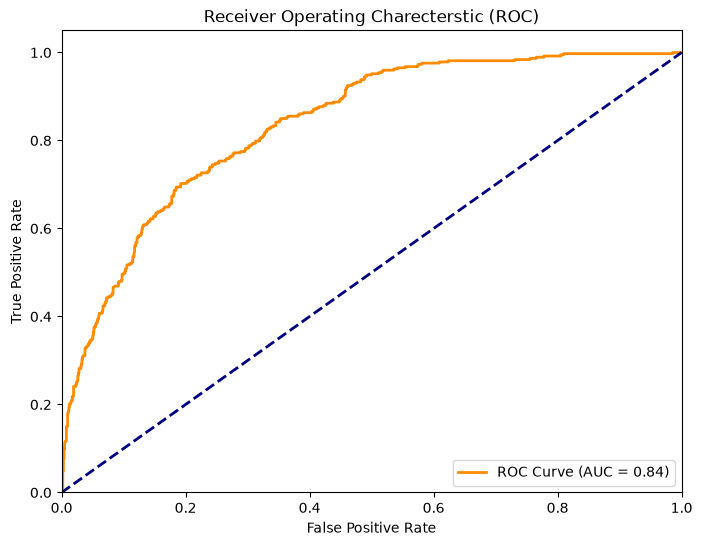

In [36]:
plt.figure(figsize=(8,6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC Curve (AUC = {roc_auc:.2f})')
plt.plot([0,1],[0,1],color='navy',lw=2,linestyle='--')
plt.xlim([0.0,1.0])
plt.ylim([0.0,1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Charecterstic (ROC)')
plt.legend(loc='lower right')
plt.show()

In [37]:
import shap
explainer = shap.TreeExplainer(best_model)
shap_values = explainer.shap_values(X_test)

/home/jaswanth/churn_project/churn_env/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


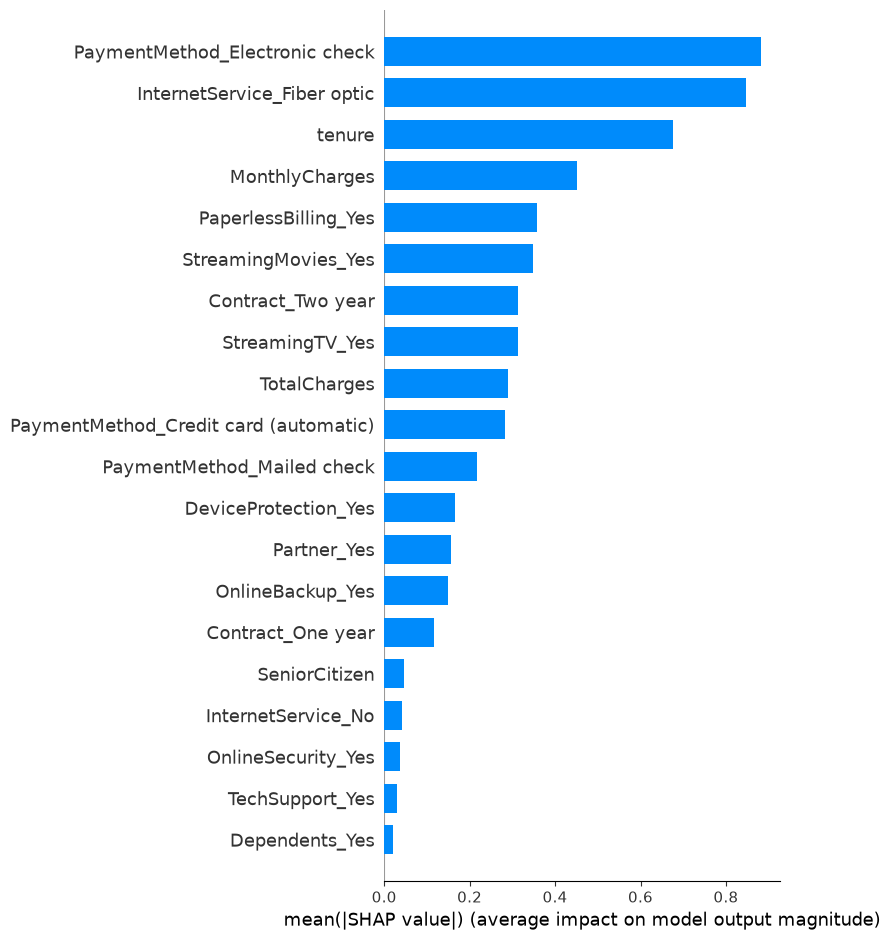

In [38]:
shap.summary_plot(shap_values,X_test, plot_type="bar")

In [40]:
import joblib
joblib.dump(best_model, 'optimized_churn_model.pkl')
joblib.dump(X_train.columns.tolist(),'model_featues.pkl')

['model_featues.pkl']